**Práctica 4**

Alumno: Antonio Ruz Bejarano

Enunciado: Crear un modelo usando (transfer learning) alguno de los modelos pre-entrenados de base vistos en clase para clasificar el conjunto de datos (MNIST) utilizado en las prácticas anteriores. Puede utilizar el siguiente cuaderno como referencia. Comparar los resultados de distintas propuestas (modelos), visualizando los resultados comparativos de forma gráfica y numérica.

 ¿Qué configuración obtiene el mejor rendimiento para ese conjunto de datos? Guarde el mejor modelo entrenado en disco para futuro uso.

NOTA: Los modelos pre-entrenados de Tensorflow se encuentran en tf.keras.application y los de PyTorch en torchvision.models

In [ ]:
#Imports necesarios y fijación de semilla
import os
import random
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.applications import VGG16, ResNet50
from tensorflow.keras import layers, models, callbacks
import matplotlib.pyplot as plt
import pandas as pd
import time
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

In [ ]:
# Cargar datos y preprocesamiento
(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = np.expand_dims(x_train, axis=-1).astype('float32')
x_test = np.expand_dims(x_test, axis=-1).astype('float32')

print(f"Dimensiones de train: {x_train.shape} | Dimensiones de test: {x_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Dimensiones de train: (60000, 28, 28, 1) | Dimensiones de test: (10000, 28, 28, 1)


A continuación dejo los 3 expermientos a probar y dejo la entrada de las imagenes listas para que los modelos lo puedan usar

In [ ]:
# Adaptamos el preprocesado para que los modelos lo puedan leer y no den error
preprocesado_entrada = models.Sequential([
    layers.Resizing(224, 224),
    layers.Lambda(lambda x: tf.image.grayscale_to_rgb(x))
], name="adaptador_224x224x3")

#Experimento 1: VGG16
base_vgg16 = VGG16(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
base_vgg16.trainable = False

modelo_vgg16 = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    preprocesado_entrada,
    layers.Lambda(tf.keras.applications.vgg16.preprocess_input),
    base_vgg16,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
], name="VGG16_FeatureExtractor")

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [ ]:
#Experimento 2: ResNet50
base_resnet50 = ResNet50(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
base_resnet50.trainable = False

modelo_resnet50 = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    preprocesado_entrada,
    layers.Lambda(tf.keras.applications.resnet50.preprocess_input),
    base_resnet50,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
], name="ResNet50_FeatureExtractor")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


In [ ]:
# Experimento 3: ResNet50 (Afinado de las últimas capas) ---
base_resnet50_ft = ResNet50(include_top=False, weights='imagenet', input_shape=(224, 224, 3))
base_resnet50_ft.trainable = True
# Congelamos todo excepto las últimas 15 capas
for layer in base_resnet50_ft.layers[:-15]:
    layer.trainable = False

modelo_resnet50_ft = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    preprocesado_entrada,
    layers.Lambda(tf.keras.applications.resnet50.preprocess_input),
    base_resnet50_ft,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
], name="ResNet50_FineTuning")

Ahora damos el entrenamiento, lo he hecho de forma que para cada época salga cuál es su train loss, val loss y val acc. Finalmente dará el tiempo que ha tardado y la evaluación en los tests.

In [ ]:
class ResumenEpocaCallback(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        tr_loss = logs.get('loss', 0.0)
        vl_loss = logs.get('val_loss', 0.0)
        vl_acc  = logs.get('val_accuracy', 0.0) * 100
        print(f"  -> Época {epoch+1:02d} | Train Loss: {tr_loss:.4f} | Val Loss: {vl_loss:.4f} | Val Acc: {vl_acc:.2f}%")

propuestas = {
    "VGG16": (modelo_vgg16, 1e-3),
    "ResNet50": (modelo_resnet50, 1e-3),
    "ResNet50 (Afinado)": (modelo_resnet50_ft, 1e-4)
}

historiales = {}
resumen_resultados = []
EPOCHS = 5
BATCH_SIZE = 64

for nombre, (modelo, lr) in propuestas.items():
    print(f"\n Iniciando: {nombre}")
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    inicio = time.time()
    history = modelo.fit(
        x_train, y_train,
        validation_data=(x_test, y_test),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=0,
        callbacks=[ResumenEpocaCallback()]
    )
    duracion = time.time() - inicio

    test_loss, test_acc = modelo.evaluate(x_test, y_test, verbose=0)

    historiales[nombre] = history.history
    resumen_resultados.append({
        "Modelo": nombre,
        "Test Accuracy (%)": round(test_acc * 100, 2),
        "Test Loss": round(test_loss, 4),
        "Tiempo Total (s)": round(duracion, 1),
        "Objeto_Modelo": modelo
    })


 Iniciando: VGG16
  -> Época 01 | Train Loss: 0.2870 | Val Loss: 0.0997 | Val Acc: 96.84%
  -> Época 02 | Train Loss: 0.1082 | Val Loss: 0.0746 | Val Acc: 97.63%
  -> Época 03 | Train Loss: 0.0858 | Val Loss: 0.0728 | Val Acc: 97.66%
  -> Época 04 | Train Loss: 0.0732 | Val Loss: 0.0623 | Val Acc: 98.03%
  -> Época 05 | Train Loss: 0.0623 | Val Loss: 0.0647 | Val Acc: 98.02%

 Iniciando: ResNet50
  -> Época 01 | Train Loss: 0.2225 | Val Loss: 0.0814 | Val Acc: 97.43%
  -> Época 02 | Train Loss: 0.0968 | Val Loss: 0.0689 | Val Acc: 97.79%
  -> Época 03 | Train Loss: 0.0763 | Val Loss: 0.0626 | Val Acc: 97.89%
  -> Época 04 | Train Loss: 0.0697 | Val Loss: 0.0486 | Val Acc: 98.39%
  -> Época 05 | Train Loss: 0.0590 | Val Loss: 0.0522 | Val Acc: 98.27%

 Iniciando: ResNet50 (Afinado)
  -> Época 01 | Train Loss: 0.1525 | Val Loss: 0.0374 | Val Acc: 98.87%
  -> Época 02 | Train Loss: 0.0347 | Val Loss: 0.0291 | Val Acc: 99.13%
  -> Época 03 | Train Loss: 0.0227 | Val Loss: 0.0268 | Val Acc

Como podemos observar mediante los resúmenes de como ha ido yendo época por época se concluye que el que tiene mejor val acc es el 3º experimento que acaba con un 99.29%. Ahora vamos a ver cuál es el mejor tardando menos tiempo y dandonos un accuracy decente en la visualización con las gráficas.


============================== RESUMEN NUMÉRICO ==============================
            Modelo  Test Accuracy (%)  Test Loss  Tiempo Total (s)
             VGG16              98.02     0.0647            1538.0
          ResNet50              98.27     0.0522            1113.5
ResNet50 (Afinado)              99.29     0.0318            1230.2


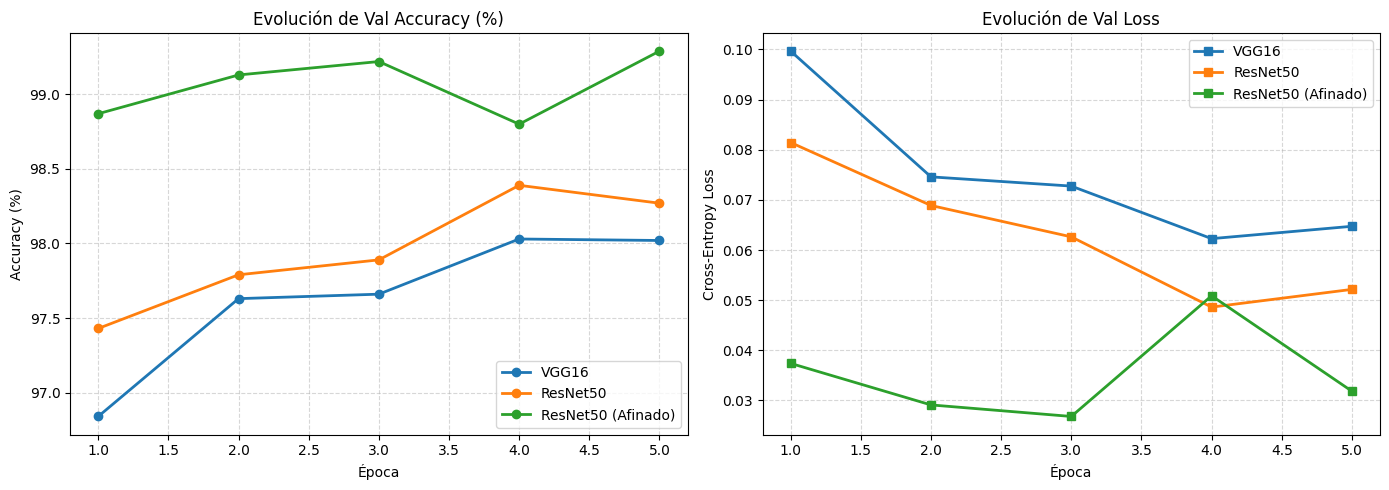

In [ ]:
# Tabla resumen
df_comparativa = pd.DataFrame(resumen_resultados).drop(columns=["Objeto_Modelo"])
print("\n" + "="*30 + " RESUMEN NUMÉRICO " + "="*30)
print(df_comparativa.to_string(index=False))

# Gráficas de Val Loss y Val Accuracy
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_range = range(1, EPOCHS + 1)

for nombre, hist in historiales.items():
    axes[0].plot(epochs_range, np.array(hist['val_accuracy']) * 100, marker='o', linewidth=2, label=nombre)
    axes[1].plot(epochs_range, hist['val_loss'], marker='s', linewidth=2, label=nombre)

axes[0].set_title('Evolución de Val Accuracy (%)')
axes[0].set_xlabel('Época')
axes[0].set_ylabel('Accuracy (%)')
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

axes[1].set_title('Evolución de Val Loss')
axes[1].set_xlabel('Época')
axes[1].set_ylabel('Cross-Entropy Loss')
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

plt.tight_layout()
plt.show()

Teniendo esta tabla resumen podemos sacar ciertas conclusiones:

El modelo que obtiene el mejor rendimiento se ve claramente que es el ResNet50 afinado, alcanzando su pico máximo en la última época con un 99.29% de accuracy y la menor pérdida (0.0318). Por otra parte, podemos observar cómo los modelos con la base congelada se acaban estancando sobre el 98%, mientras que al afinar las últimas capas el modelo sigue aprendiendo y mejorando en cada época. Además, a nivel de tiempo este 3º experimento tarda unos 1230.2 segundos, que es solo un par de minutos más que el ResNet50 congelado (1113.5 s) y bastante menos que VGG16 (1538.0 s), por lo que compensa totalmente esa subida de acierto. Por estas razones el mejor modelo final es el 3º, teniendo también claro que era necesario ponerle un learning rate más bajo (1e-4) para que, al adaptar las capas finales, los gradientes no destruyeran los pesos pre-entrenados que ya venían de ImageNet.

In [ ]:
# Guardado en disco del mejor modelo
mejor_entrada = max(resumen_resultados, key=lambda x: x["Test Accuracy (%)"])
mejor_modelo = mejor_entrada["Objeto_Modelo"]
mejor_nombre = mejor_entrada["Modelo"]

ruta_guardado = "mejor_modelo_mnist_tl.keras"
mejor_modelo.save(ruta_guardado)
print(f"\nMejor configuración: {mejor_nombre} con {mejor_entrada['Test Accuracy (%)']}% de Test Accuracy.")
print(f"Modelo guardado en disco: '{ruta_guardado}'")


Mejor configuración: ResNet50 (Afinado) con 99.29% de Test Accuracy.
Modelo guardado en disco: 'mejor_modelo_mnist_tl.keras'
